# 04 · Mengubah narasi pengaduan menjadi informasi yang dapat diperiksa

**Durasi 50 menit · peserta umum · CPU**

Hasil belajar: membaca label BIO, melatih NER, membedakan nama entitas dari peran, mengekstrak informasi ke JSON dengan bukti teks, serta menemukan informasi yang terlewat atau salah peran.

| Tahap | Menit |
|---|---:|
| Persiapan | 5 |
| Entitas dan BIO | 7 |
| Melatih dan mengevaluasi NER | 12 |
| Aduan sintetis, aturan, dan JSON | 12 |
| Evaluasi bukti dan peran | 9 |
| Latihan dan penutup | 5 |

**Hubungan dengan slide:** NERGrit, BIO, peran orang, dua jenis kesalahan ekstraksi, dan penelusuran ke kalimat asal. Praktik memakai **CRF** untuk NER dan **aturan yang dapat dibaca** untuk ekstraksi aduan. Bagian akhir menyiapkan prompt LLM, tetapi tidak memanggil layanan LLM/API. Semua evaluasi inti dapat dijalankan offline setelah instalasi.

NERGrit adalah korpus publik umum, bukan laporan kepolisian. Aduan lokal seluruhnya fiktif buatan LLM; label acuannya belum ditinjau manusia.


## 1. Persiapan · 5 menit

Jalankan sel secara berurutan melalui **Runtime → Run all** (Colab) atau **Run → Run All Cells** (Jupyter).
Di komputer: jalankan `pip install -r requirements.txt` sekali sebelum membuka notebook.
Di Colab: buka notebook ini, lalu unggah ZIP folder materi kb_kik saat diminta. Alternatifnya, mount Google Drive dan isi `PROJECT_ROOT` dengan lokasi repo.
Tidak perlu GPU, API key, atau akun layanan AI. Internet hanya diperlukan untuk instalasi awal/unggah ZIP. Versi paket yang dipakai saat pengujian dicantumkan di `requirements.txt`.


In [1]:
import importlib.util, subprocess, sys
# Hanya memasang paket yang belum ada; pada environment yang sudah siap, sel ini offline.
packages = {"numpy":"numpy==2.2.6", "pandas":"pandas==2.2.3",
            "sklearn":"scikit-learn==1.6.1", "matplotlib":"matplotlib==3.10.3"}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("Paket dasar tersedia. Python", sys.version.split()[0])

if importlib.util.find_spec("sklearn_crfsuite") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", "sklearn-crfsuite==0.5.0"])

Paket dasar tersedia. Python 3.12.14


In [2]:
TOPIC = '04_ekstraksi_pengaduan'
from pathlib import Path
import os,sys,json,zipfile,importlib.util

# Isi lokasi folder repo di sini jika deteksi otomatis gagal.
PROJECT_ROOT = os.environ.get("POLRI_TUTORIAL_ROOT", "")
def is_repo(path):
    return (path / "dataset/01_smsa_final_train.csv").is_file() and (path / "notebook").is_dir()
def find_repo():
    if PROJECT_ROOT:
        return Path(PROJECT_ROOT).expanduser().resolve()
    return next((p for p in [Path.cwd(),*Path.cwd().parents] if is_repo(p)), None)

ROOT = find_repo()
try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if ROOT is None and IN_COLAB:
    from google.colab import files
    print("Unggah satu ZIP folder materi kb_kik agar notebook dan dataset tersedia.")
    uploaded = files.upload()
    archives = [name for name in uploaded if name.lower().endswith(".zip")]
    if len(archives) != 1:
        raise ValueError("Unggah tepat satu ZIP folder materi kb_kik.")
    target = Path(os.environ.get("POLRI_COLAB_UPLOAD_DIR", "/content/polri_tutorial"))
    target.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(archives[0]) as archive:
        for item in archive.infolist():
            if not (target / item.filename).resolve().is_relative_to(target.resolve()):
                raise ValueError("Path ZIP tidak aman.")
        archive.extractall(target)
    roots = [p.parent for p in target.rglob("README.md") if is_repo(p.parent)]
    if len(roots) != 1:
        raise ValueError("Struktur ZIP tidak sesuai; isi PROJECT_ROOT secara manual.")
    ROOT = roots[0]
if ROOT is None or not is_repo(ROOT):
    raise FileNotFoundError("Ekstrak repo lengkap atau isi PROJECT_ROOT dengan lokasi repo.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,HTML
from pathlib import Path
import json,re,unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report,confusion_matrix,ConfusionMatrixDisplay,
                             f1_score,precision_score,recall_score)
SEED=42
LABELS=['negative','neutral','positive']
IE_FIELDS=['pelapor','korban','terlapor','saksi','waktu_kejadian','lokasi_kejadian','nominal_disebut','bukti_tersedia']
np.random.seed(SEED)
pd.set_option("display.max_colwidth",115)
plt.rcParams.update({"figure.dpi":110,"font.size":10,"axes.spines.top":False,"axes.spines.right":False})
DATASET = ROOT / "dataset"
OUT = ROOT / "outputs" / TOPIC
OUT.mkdir(parents=True,exist_ok=True)
print("Repo:",ROOT.name,"| Hasil:",OUT.relative_to(ROOT))

Repo: kb_kik | Hasil: outputs\04_ekstraksi_pengaduan


## 2. Mengenali entitas belum menentukan peran · 7 menit

`PERSON`, `PLACE`, `ORGANISATION` menjawab jenis entitas. Tag `B-` menandai awal, `I-` kelanjutan, `O` di luar entitas. PERSON belum berarti pelapor, korban, saksi, atau terlapor.

Satu baris data berisi satu kalimat. Kolom tokens/tags disimpan sebagai array JSON, bukan dipisah memakai koma. Teks disusun ulang dari token, sehingga tidak mempertahankan tata letak dokumen asli.


In [3]:
# Fungsi yang dipakai pada langkah berikut.
def norm(text):
    return ' '.join(unicodedata.normalize('NFKC',str(text)).casefold().split())

def load_splits(root,prefix):
    splits={s:pd.read_csv(Path(root)/'dataset'/f'{prefix}_final_{s}.csv') for s in ['train','val','test']}
    seen=[]
    for s,df in splits.items():
        assert not df['id'].duplicated().any(),f'Duplicate id: {s}'
        column='content_cleaned' if 'content_cleaned' in df else 'content'
        assert df[column].notna().all() and df[column].str.strip().ne('').all()
        current=set(df[column].map(norm));assert len(current)==len(df),f'Duplicate input: {s}'
        for previous in seen:assert not previous & current,'Cross-split text overlap'
        seen.append(current)
    ids=[set(df.id) for df in splits.values()]
    assert all(not ids[i]&ids[j] for i in range(3) for j in range(i+1,3))
    return splits['train'],splits['val'],splits['test']

In [4]:
ner_train,ner_val,ner_test = load_splits(ROOT,"04_nergrit")
for df in [ner_train,ner_val,ner_test]:
    df["token_list"] = df.tokens.map(json.loads)
    df["tag_list"] = df.ner_tags.map(json.loads)
    assert all(len(a)==len(b) for a,b in zip(df.token_list,df.tag_list))
display(pd.DataFrame({"split":["train","val","test"],"kalimat":[len(ner_train),len(ner_val),len(ner_test)]}))
display(pd.DataFrame({"token":ner_train.iloc[0].token_list,"tag":ner_train.iloc[0].tag_list}))
print("Jenis tag:", sorted({tag for tags in ner_train.tag_list for tag in tags}))

,split,kalimat
0,train,1672
1,val,209
2,test,209


,token,tag
0,Kontribusinya,O
1,terhadap,O
2,industri,O
3,musik,O
4,telah,O
5,mengumpulkan,O
6,banyak,O
7,prestasi,O
8,termasuk,O
9,lima,O


Jenis tag: ['B-ORGANISATION', 'B-PERSON', 'B-PLACE', 'I-ORGANISATION', 'I-PERSON', 'I-PLACE', 'O']


## 3. Model NER belajar pola urutan · 12 menit

CRF memakai ciri kata, huruf besar, akhiran, serta kata sebelum/sesudahnya. Ia belajar urutan BIO dari train. Kita bandingkan dua nilai regularisasi memakai F1 **entitas lengkap** di validation. Bagian bersama `crf_features` dapat dibaca di sel fungsi pada notebook ini.

Entitas baru dianggap benar jika **jenis dan seluruh rentang token cocok**. Akurasi token dapat terlihat tinggi karena banyak token O. Menebak O untuk semua token tidak menemukan entitas apa pun.


In [5]:
# Fungsi yang dipakai pada langkah berikut.
def crf_features(tokens):
    output=[]
    for i,w in enumerate(tokens):
        f={'bias':1.,'word':w.lower(),'suffix2':w[-2:].lower(),'suffix3':w[-3:].lower(),
           'upper':w.isupper(),'title':w.istitle(),'digit':w.isdigit()}
        for offset,name in [(-1,'prev'),(1,'next')]:
            j=i+offset
            if 0<=j<len(tokens):f[name]=tokens[j].lower();f[name+'_title']=tokens[j].istitle()
            else:f['BOS' if offset<0 else 'EOS']=True
        output.append(f)
    return output

def bio_entities(tags):
    """Strict IOB2 spans (type, start token, exclusive end); orphan I is ignored."""
    entities=set();active=None;start=None
    for i,tag in enumerate(list(tags)+['O']):
        prefix,kind=(tag.split('-',1) if '-' in tag else ('O',''))
        continuation=prefix=='I' and active==kind
        if active is not None and not continuation:
            entities.add((active,start,i));active=None;start=None
        if prefix=='B':active=kind;start=i
    return entities

def entity_report(y_true,y_pred):
    assert len(y_true)==len(y_pred)
    all_true=set();all_pred=set()
    for i,(a,b) in enumerate(zip(y_true,y_pred)):
        assert len(a)==len(b)
        all_true.update((i,)+e for e in bio_entities(a))
        all_pred.update((i,)+e for e in bio_entities(b))
    types=sorted({e[1] for e in all_true|all_pred})
    rows=[]
    for kind in types+['micro']:
        gold={e for e in all_true if kind=='micro' or e[1]==kind}
        pred={e for e in all_pred if kind=='micro' or e[1]==kind}
        tp=len(gold&pred);fp=len(pred-gold);fn=len(gold-pred)
        p=tp/(tp+fp) if tp+fp else 0.;r=tp/(tp+fn) if tp+fn else 0.
        rows.append(dict(entity=kind,precision=p,recall=r,f1=2*p*r/(p+r) if p+r else 0.,support=len(gold),tp=tp,fp=fp,fn=fn))
    return pd.DataFrame(rows).set_index('entity')

In [6]:
import sklearn_crfsuite
from sklearn.metrics import accuracy_score
X_train = [crf_features(t) for t in ner_train.token_list]
X_val = [crf_features(t) for t in ner_val.token_list]
y_train = ner_train.tag_list.tolist(); y_val = ner_val.tag_list.tolist()
models,rows = {},[]
for regularization in [0.1,0.5]:
    candidate = sklearn_crfsuite.CRF(algorithm="lbfgs",c1=regularization,c2=regularization,
        max_iterations=60,all_possible_transitions=True)
    candidate.fit(X_train,y_train)
    prediction = candidate.predict(X_val)
    score = entity_report(y_val,prediction).loc["micro","f1"]
    models[regularization]=candidate;rows.append({"regularization":regularization,"entity_f1":score})
validation_scores = pd.DataFrame(rows).sort_values("entity_f1",ascending=False)
display(validation_scores.round(3))
best_reg = float(validation_scores.iloc[0].regularization)
ner_model = models[best_reg]

,regularization,entity_f1
0,0.1,0.663
1,0.5,0.648


,precision,recall,f1,support,tp,fp,fn
entity,,,,,,,
ORGANISATION,0.603,0.379,0.465,124,47,31,77
PERSON,0.701,0.623,0.660,207,129,55,78
PLACE,0.774,0.689,0.729,357,246,72,111
micro,0.728,0.613,0.666,688,422,158,266


Akurasi token jika selalu O: 0.813 | F1 entitas: 0


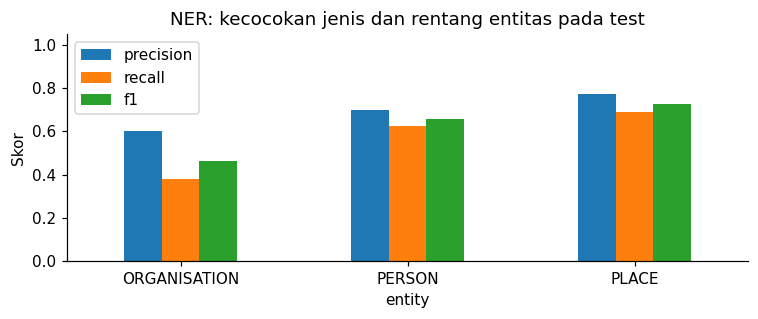

,token,acuan,prediksi
0,Joetata,B-PERSON,B-PERSON
1,Hadihardaja,I-PERSON,I-PERSON
2,dan,O,O
3,dihadiri,O,O
4,oleh,O,O
5,Rektor,O,B-ORGANISATION
6,Undip,B-ORGANISATION,I-ORGANISATION
7,Prof,O,I-ORGANISATION
8,.,O,O


In [7]:
ner_prediction = ner_model.predict([crf_features(t) for t in ner_test.token_list])
ner_report = entity_report(ner_test.tag_list.tolist(),ner_prediction)
display(ner_report.round(3))
flat_true = [tag for tags in ner_test.tag_list for tag in tags]
all_o_accuracy = accuracy_score(flat_true,["O"]*len(flat_true))
print("Akurasi token jika selalu O:",round(all_o_accuracy,3),"| F1 entitas: 0")
fig,ax=plt.subplots(figsize=(7,3))
ner_report.drop(index="micro")[["precision","recall","f1"]].plot.bar(ax=ax)
ax.set(title="NER: kecocokan jenis dan rentang entitas pada test",ylim=(0,1.05),ylabel="Skor")
ax.tick_params(axis="x",rotation=0);fig.tight_layout();fig.savefig(OUT / "ner_entity_metrics.png",dpi=150);plt.show();plt.close(fig)
ner_report.to_csv(OUT / "ner_report.csv")
error_index = next((i for i,(a,b) in enumerate(zip(ner_test.tag_list,ner_prediction)) if a!=list(b)),0)
display(pd.DataFrame({"token":ner_test.iloc[error_index].token_list,
                      "acuan":ner_test.iloc[error_index].tag_list,"prediksi":ner_prediction[error_index]}))

## 4. Aduan sintetis menjadi JSON dengan bukti · 12 menit

Kita pindah ke tugas berbeda: **ekstraksi peran dan informasi aduan**.24 aduan dibagi12 train,6 validation,6 test. Train untuk menyusun aturan/contoh prompt; validation untuk memeriksa pilihan, test untuk evaluasi akhir. Ini korpus kecil untuk demonstrasi, bukan untuk membuktikan ketepatan operasional atau fine-tuning LLM.

Setiap isian berupa kutipan dan posisi karakter (`start` inklusif, `end` eksklusif). `[]` berarti informasi tidak tersedia/tidak memenuhi aturan. Nominal uang yang disebut **bukan otomatis kerugian**: dapat berupa tuntutan, harga beli, estimasi, atau pengembalian. Bukti yang belum diperoleh tidak masuk `bukti_tersedia`.


In [8]:
aduan_train,aduan_val,aduan_test = load_splits(ROOT,"04_aduan_sintetis")
def read_gold(split):
    return [json.loads(line) for line in (DATASET / f"04_aduan_sintetis_gold_{split}.jsonl").read_text(encoding="utf-8").splitlines()]
gold_train, gold_val = read_gold("train"),read_gold("val")
example = aduan_train.iloc[0]
display(Markdown("**Aduan fiktif train:** " + example.content))
display(next(g for g in gold_train if g["id"]==example.id))

# Fungsi aturan tidak menerima gold/id, hanya teks. Implementasi ada di sel fungsi di notebook ini.
print("Baca fungsi extract_rules pada sel di atas; fungsi hanya menerima teks, tanpa id atau label acuan.")

**Aduan fiktif train:** Saya Nara Fiktif memesan sepatu dari @TOKO_DEMO_A. Pada 2 Oktober 2026 saya mentransfer Rp450.000. Barang tidak datang dan akun itu menghilang. Nama penerima tertulis Danu Fiktif, tetapi saya tidak tahu siapa yang mengendalikan akun tersebut. Saya menyimpan bukti transfer.

{'id': 'A01',
 'fields': {'pelapor': [{'text': 'Nara Fiktif', 'start': 5, 'end': 16}],
  'korban': [{'text': 'Nara Fiktif', 'start': 5, 'end': 16}],
  'terlapor': [],
  'saksi': [],
  'waktu_kejadian': [{'text': '2 Oktober 2026', 'start': 56, 'end': 70}],
  'lokasi_kejadian': [],
  'nominal_disebut': [{'text': 'Rp450.000.', 'start': 88, 'end': 98}],
  'bukti_tersedia': [{'text': 'bukti transfer', 'start': 258, 'end': 272}]},
 'review_notes': 'Danu adalah nama penerima transfer, bukan otomatis terlapor; lokasi tidak dinyatakan.'}

Baca fungsi extract_rules pada sel di atas; fungsi hanya menerima teks, tanpa id atau label acuan.


In [9]:
# Fungsi yang dipakai pada langkah berikut.
def empty_extraction():return {k:[] for k in IE_FIELDS}

def add_span(fields,key,text,value):
    for m in re.finditer(re.escape(value),text):
        span={'text':value,'start':m.start(),'end':m.end()}
        if span not in fields[key]:fields[key].append(span)
        break

def validate_extraction(text,fields):
    """Structural/evidence validation. Does NOT establish that a role is semantically correct."""
    if not isinstance(fields,dict) or set(fields)!=set(IE_FIELDS):raise ValueError('Missing/unknown extraction fields')
    for key,values in fields.items():
        if not isinstance(values,list):raise ValueError(f'{key} must be a list')
        seen=set()
        for v in values:
            if not isinstance(v,dict) or set(v)!={'text','start','end'}:raise ValueError('Invalid evidence object')
            a,b=v['start'],v['end']
            if type(a) is not int or type(b) is not int or not 0<=a<b<=len(text):raise ValueError('Invalid offsets')
            if text[a:b]!=v['text']:raise ValueError('Evidence is not an exact source substring')
            if (a,b) in seen:raise ValueError('Duplicate evidence span')
            seen.add((a,b))
    return fields

def extract_rules(text):
    """Inspectable demonstration rules; built from train cases, deliberately incomplete."""
    out=empty_extraction();person=r'[A-Z][a-z]+ Fiktif'
    m=re.search(r'(?:[Nn]ama saya |[Ss]aya(?:, )?\s*)('+person+r')',text)
    if m:add_span(out,'pelapor',text,m[1])
    represented=re.search(r'(?:ayah saya, |anak saya, |kakak saya, |teman saya, |Pemilik barang adalah )('+person+r')',text)
    if represented:add_span(out,'korban',text,represented[1])
    elif m and re.search(r'(?:saya|Saya).*(?:menerima|kehilangan|memesan|membeli|membayar|mentransfer|mengirim|dipukul|mengadukan|mengancam|hilang|rusak|pecah|transfer)',text):
        add_span(out,'korban',text,m[1])
    for pattern in [r'(?:mengadukan|melaporkan) ('+person+r')',r'dipanggil ([A-Z][a-z]+)',r'(@[A-Z_0-9]+)']:
        for m in re.finditer(pattern,text):add_span(out,'terlapor',text,m[1])
    for m in re.finditer(r'('+person+r') (?:menyaksikan|menemani|mengatakan|membaca|ada di dekat)',text):add_span(out,'saksi',text,m[1])
    # Location patterns intentionally conservative, may still get routes/discovery places wrong.
    for m in re.finditer(r'(?:di |dari )(?:depan )?((?:Terminal|Rumah|Jalan|Kios|Asrama|Parkir|Gedung|Kedai|Kantor|Pasar|Gang|Bengkel|Lapangan|Gudang|Halte) Contoh [A-Z][a-z]+(?: [A-Z][a-z]+)?)',text):add_span(out,'lokasi_kejadian',text,m[1])
    for m in re.finditer(r'(?:pagi )?\d{1,2} Oktober 2026(?: (?:sekitar )?pukul \d{1,2}\.\d{2})?|kemarin sore|tadi malam',text):add_span(out,'waktu_kejadian',text,m[0])
    for m in re.finditer(r'Rp[\d.]+',text):add_span(out,'nominal_disebut',text,m[0])
    # Available evidence only; a nearby negation rejects a candidate rather than fabricating it.
    for pattern in [r'[Bb]ukti transfer',r'[Tt]angkapan layar(?: pesan| iklan)?',r'[Ff]oto (?:sepeda|pagar rusak|kerusakan|tas|luka|motor)',r'[Vv]ideo pembukaan paket',r'[Ss]urel tiket',r'kuitansi digital',r'[Ss]urat asli',r'[Cc]atatan stok',r'[Ss]alinan percakapan',r'riwayat percakapan',r'[Tt]iket parkir',r'\bSTNK\b',r'\bkunci\b']:
        for m in re.finditer(pattern,text):
            clause=text[max(0,text.rfind('.',0,m.start())+1):text.find('.',m.end()) if text.find('.',m.end())>=0 else len(text)]
            if not re.search(r'belum|terhapus|tidak (?:ada|punya|membawa)',clause,re.I):add_span(out,'bukti_tersedia',text,m[0])
    return validate_extraction(text,out)

def extraction_report(gold,pred):
    assert {g['id'] for g in gold}=={p['id'] for p in pred}
    gs=set();ps=set()
    for source,dest in [(gold,gs),(pred,ps)]:
        for g in source:
            for k,spans in g['fields'].items():
                for s in spans:dest.add((g['id'],k,s['start'],s['end'],s['text']))
    rows=[]
    for k in IE_FIELDS+['micro']:
        a={v for v in gs if k=='micro' or v[1]==k};b={v for v in ps if k=='micro' or v[1]==k}
        tp=len(a&b);fp=len(b-a);fn=len(a-b);p=tp/(tp+fp) if tp+fp else 0.;r=tp/(tp+fn) if tp+fn else 0.
        rows.append(dict(field=k,precision=p,recall=r,f1=2*p*r/(p+r) if p+r else 0.,support=len(a),tp=tp,fp=fp,fn=fn))
    return pd.DataFrame(rows).set_index('field')

In [10]:
example_fields = extract_rules(example.content)
validate_extraction(example.content,example_fields)
print(json.dumps(example_fields,ensure_ascii=False,indent=2))

# Tampilkan bukti sebagai sorotan; HTML-escape agar teks sumber tidak menjadi kode HTML.
import html
selected = example_fields["pelapor"] + example_fields["nominal_disebut"]
cursor=0;parts=[]
for span in sorted(selected,key=lambda s:s["start"]):
    if span["start"]<cursor:continue
    parts.append(html.escape(example.content[cursor:span["start"]]))
    parts.append("<mark>"+html.escape(span["text"])+"</mark>");cursor=span["end"]
parts.append(html.escape(example.content[cursor:]))
display(HTML("<p style='line-height:1.9'>"+"".join(parts)+"</p>"))
val_predictions = [{"id":r.id,"fields":extract_rules(r.content)} for r in aduan_val.itertuples()]
display(extraction_report(gold_val,val_predictions).round(3))

{
  "pelapor": [
    {
      "text": "Nara Fiktif",
      "start": 5,
      "end": 16
    }
  ],
  "korban": [
    {
      "text": "Nara Fiktif",
      "start": 5,
      "end": 16
    }
  ],
  "terlapor": [
    {
      "text": "@TOKO_DEMO_A",
      "start": 37,
      "end": 49
    }
  ],
  "saksi": [],
  "waktu_kejadian": [
    {
      "text": "2 Oktober 2026",
      "start": 56,
      "end": 70
    }
  ],
  "lokasi_kejadian": [],
  "nominal_disebut": [
    {
      "text": "Rp450.000.",
      "start": 88,
      "end": 98
    }
  ],
  "bukti_tersedia": [
    {
      "text": "bukti transfer",
      "start": 258,
      "end": 272
    }
  ]
}


,precision,recall,f1,support,tp,fp,fn
field,,,,,,,
pelapor,1.000,1.000,1.000,6,6,0,0
korban,1.000,1.000,1.000,6,6,0,0
terlapor,1.000,1.000,1.000,4,4,0,0
saksi,0.000,0.000,0.000,2,0,0,2
waktu_kejadian,0.667,0.667,0.667,6,4,2,2
lokasi_kejadian,1.000,0.500,0.667,4,2,0,2
nominal_disebut,1.000,1.000,1.000,4,4,0,0
bukti_tersedia,0.857,0.857,0.857,7,6,1,1
micro,0.914,0.821,0.865,39,32,3,7


**Periksa sekarang:** apakah nama rekening otomatis terlapor? Apakah tanggal menemukan kehilangan sama dengan waktu pencurian? Apakah nominal yang diminta sudah menjadi kerugian? Aturan dapat menghasilkan kutipan yang ada tetapi **perannya salah**.

Validator di atas hanya memastikan JSON dan kutipan sesuai sumber. Ia belum memeriksa makna peran. Karena itu kita membutuhkan label acuan dan verifikasi manusia. Aturan dasar ini sengaja konservatif/tidak lengkap; sebagian informasi akan terlewat.

## 5. Evaluasi isian dan rentang pada test · 9 menit

Aturan sekarang dikunci. Ukur precision, recall, dan F1 per field dengan kecocokan **id,field,start,end,text**. Nominal yang benar tidak menutupi kegagalan menentukan peran. Rentang yang beda satu kata dihitung berbeda, sehingga metrik ketat harus dibaca bersama contoh.


In [11]:
# Fungsi yang dipakai pada langkah berikut.
def save_json(path,value):
    Path(path).write_text(json.dumps(value,ensure_ascii=False,indent=2),encoding='utf-8')

In [12]:
gold_test = read_gold("test")
predictions = [{"id":r.id,"fields":extract_rules(r.content)} for r in aduan_test.itertuples()]
by_id = aduan_test.set_index("id").content.to_dict()
for prediction in predictions:validate_extraction(by_id[prediction["id"]],prediction["fields"])
ie_report = extraction_report(gold_test,predictions)
display(ie_report.round(3))
ie_report.to_csv(OUT / "complaint_extraction_report.csv")
save_json(OUT / "complaint_predictions.json",predictions)
save_json(OUT / "metrics.json",{"ner_best_regularization":best_reg,
    "ner_entity_f1":float(ner_report.loc["micro","f1"]),
    "complaint_exact_evidence_f1":float(ie_report.loc["micro","f1"]),
    "synthetic_test_documents":len(aduan_test)})

gold_by_id={g["id"]:g for g in gold_test}
review_rows=[]
for prediction in predictions:
    g=gold_by_id[prediction["id"]]
    for field in IE_FIELDS:
        if g["fields"][field]!=prediction["fields"][field]:
            review_rows.append({"id":g["id"],"field":field,
                "acuan":[s["text"] for s in g["fields"][field]],
                "prediksi":[s["text"] for s in prediction["fields"][field]],"catatan":g["review_notes"]})
display(pd.DataFrame(review_rows).head(10))

,precision,recall,f1,support,tp,fp,fn
field,,,,,,,
pelapor,1.0,1.000,1.000,6,6,0,0
korban,1.0,1.000,1.000,6,6,0,0
terlapor,1.0,1.000,1.000,3,3,0,0
saksi,1.0,1.000,1.000,2,2,0,0
waktu_kejadian,1.0,0.857,0.923,7,6,0,1
lokasi_kejadian,1.0,1.000,1.000,4,4,0,0
nominal_disebut,1.0,1.000,1.000,3,3,0,0
bukti_tersedia,1.0,0.667,0.800,6,4,0,2
micro,1.0,0.919,0.958,37,34,0,3


,id,field,acuan,prediksi,catatan
0,A15,waktu_kejadian,"[14 Oktober 2026 pukul 21.00, pukul 20.00]",[14 Oktober 2026 pukul 21.00],Konflik waktu belum selesai; simpan kedua klaim dan jangan memilih diam-diam.
1,A16,bukti_tersedia,[Surat asli],[],"Rp5.000.000 adalah tuntutan, bukan kerugian yang sudah terjadi."
2,A18,bukti_tersedia,[Foto kondisi sebelum dan sesudah penitipan],[],Pemilik bengkel tidak otomatis terlapor; kerugian belum dihitung.


In [13]:
# Tantangan sintetis tambahan, terpisah dari skor test: negasi dapat membalik peran.
challenge_text = "Nama saya Nara Fiktif. Saya tidak melaporkan Danu Fiktif; saya hanya bertanya prosedur."
challenge_fields = extract_rules(challenge_text)
validate_extraction(challenge_text, challenge_fields)
display(pd.DataFrame({"teks":[challenge_text], "terlapor_prediksi":[[s["text"] for s in challenge_fields["terlapor"]]],
    "catatan":["Kutipan cocok dengan sumber, tetapi negasi membuat peran ini salah. Perlu pemeriksaan makna."]}))

,teks,terlapor_prediksi,catatan
0,Nama saya Nara Fiktif. Saya tidak melaporkan Danu Fiktif; saya hanya bertanya prosedur.,[Danu Fiktif],"Kutipan cocok dengan sumber, tetapi negasi membuat peran ini salah. Perlu pemeriksaan makna."


## 6. Menyiapkan prompt LLM dan verifikasi manusia · 5 menit

Prompt berikut hanya **bahan pengembangan**, bukan hasil panggilan LLM. Contoh few-shot diambil dari train. Sel ini tidak mengakses API, tidak membutuhkan key, dan tidak mengirim data. Jika nanti memakai model eksternal, gunakan hanya data fiktif serta ukur hasil dengan evaluator yang sama. Skor ekstraksi aturan di atas tidak boleh disebut skor LLM.


In [14]:
few_shot = gold_train[0]
LLM_PROMPT = (
    "Ekstrak informasi dari narasi fiktif. Kembalikan JSON dengan field: "
    + ", ".join(IE_FIELDS) + ". Setiap field adalah daftar kutipan persis. "
    "Kosongkan jika tidak ada; jangan menebak peran dari nama rekening. "
    "Nominal disebut bukan otomatis kerugian. Bukti terhapus/belum diperoleh bukan bukti tersedia. "
    "Peran terlapor adalah klaim narator, bukan temuan bersalah. "
    "Untuk implementasi, hitung start/end dari kutipan yang benar-benar ditemukan di sumber; "
    "jika kutipan berulang, minta konteks agar lokasi tidak ambigu.\n\n"
    "Contoh train: " + aduan_train.set_index("id").loc[few_shot["id"],"content"]
    + "\nJawaban contoh: " + json.dumps({k:[s["text"] for s in v] for k,v in few_shot["fields"].items()},ensure_ascii=False)
)
print(LLM_PROMPT)
print("Output praktik tersimpan di",OUT.relative_to(ROOT))

Ekstrak informasi dari narasi fiktif. Kembalikan JSON dengan field: pelapor, korban, terlapor, saksi, waktu_kejadian, lokasi_kejadian, nominal_disebut, bukti_tersedia. Setiap field adalah daftar kutipan persis. Kosongkan jika tidak ada; jangan menebak peran dari nama rekening. Nominal disebut bukan otomatis kerugian. Bukti terhapus/belum diperoleh bukan bukti tersedia. Peran terlapor adalah klaim narator, bukan temuan bersalah. Untuk implementasi, hitung start/end dari kutipan yang benar-benar ditemukan di sumber; jika kutipan berulang, minta konteks agar lokasi tidak ambigu.

Contoh train: Saya Nara Fiktif memesan sepatu dari @TOKO_DEMO_A. Pada 2 Oktober 2026 saya mentransfer Rp450.000. Barang tidak datang dan akun itu menghilang. Nama penerima tertulis Danu Fiktif, tetapi saya tidak tahu siapa yang mengendalikan akun tersebut. Saya menyimpan bukti transfer.
Jawaban contoh: {"pelapor": ["Nara Fiktif"], "korban": ["Nara Fiktif"], "terlapor": [], "saksi": [], "waktu_kejadian": ["2 Oktob

### Latihan penutup

1. Pilih satu kesalahan peran dari tabel. Kutip kalimat yang perlu diperiksa dan jelaskan kenapa validator substring saja tidak cukup.
2. Perbaiki aturan dengan **train/validation**, bukan menyalin jawaban test ke fungsi. Jika sudah melihat test, butuhkan holdout baru untuk klaim evaluasi berikutnya.
3. Untuk kasus waktu yang bertentangan, usulkan keluaran yang mempertahankan dua klaim dan status belum pasti.

**Batas hasil:** tidak menilai pasal atau kesalahan hukum, tidak memastikan identitas orang, dan tidak otomatis menghubungkan laporan sebagai pelaku yang sama. NER umum tidak membuktikan performa pada aduan. Korpus aduan kecil, fiktif, satu generator, dan belum diaudit manusia. Semua isian yang akan dipakai perlu verifikasi sumber oleh petugas.

Sumber: [IndoNLU/NERGrit](https://github.com/IndoNLP/indonlu), [CRF tutorial](https://sklearn-crfsuite.readthedocs.io/en/latest/tutorial.html). Schema acuan: `dataset/README.md`; provenance sintetis dan konflik metadata lisensi dicatat di `dataset/README.md`.
